In [ ]:
# ================================================================
#  CELL 1 — Imports & Config
# ================================================================
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ---- Hyper-parameters ----
GRID        = 32
BATCH_SIZE  = 32
LR          = 3e-4
EPOCHS      = 200       # early stopping will fire well before this
N_TRAIN     = 500
N_VAL       = 150
DROPOUT     = 0.3
ES_PATIENCE = 20        # early-stopping patience (epochs)
THRESHOLD   = 0.5       # consistent threshold everywhere
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED        = 42

# ---- Reproducibility ----
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.makedirs('results/figures', exist_ok=True)
print(f'Device : {DEVICE}')
print(f'Config : N_TRAIN={N_TRAIN}  N_VAL={N_VAL}  BATCH={BATCH_SIZE}  LR={LR}')

Device : cuda
Config : N_TRAIN=500  N_VAL=150  BATCH=32  LR=0.0003


In [ ]:
# ================================================================
#  CELL 2 — Synthetic Dataset  (FIX #1 #2 #3 #5)
# ================================================================
class SyntheticReactionDataset(Dataset):
    """
    Generates synthetic but genuinely LEARNABLE reaction data.

    Design rationale
    ----------------
    - Reactant channels : 7 channels of random Gaussian background blobs.
      No reaction-center signal → the model cannot cheat by looking only
      at the reactant side.
    - Product channels  : same 7-channel structure, BUT channel-0 carries
      an EXTRA Gaussian blob at the reaction center (cx, cy).  This
      simulates the change that occurs at the bond-formation site.
    - Mask              : a hard binary 6×6 square at (cx, cy).
    - Every sample has a DIFFERENT random (cx, cy) sampled from
      U[6, 25] so the model must learn a GENERALIZABLE rule
      ("find the extra blob in product channel-0") rather than
      memorising a single pixel location.

    FIX vs original
    ---------------
    Original `compute_delta` hard-coded mask[10:15, 10:15] = 1 for
    every sample, and `smiles_to_tensor` returned pure random noise.
    That made the task trivially solvable by memorising one location,
    producing a fraudulently perfect test score.
    """

    def __init__(self, n_samples: int, grid_size: int = 32,
                 seed: int = 0, augment: bool = False):
        self.g       = grid_size
        self.augment = augment
        rng = np.random.RandomState(seed)
        # Each sample gets its own independent seed so samples are diverse
        seeds = rng.randint(0, 2**30, size=n_samples)
        self.samples = [self._make_sample(int(s)) for s in seeds]

    # ------------------------------------------------------------------
    def _gaussian_map(self, cx, cy, sigma, amplitude):
        g  = self.g
        xx, yy = np.meshgrid(np.arange(g), np.arange(g))
        return amplitude * np.exp(-((xx - cx)**2 + (yy - cy)**2)
                                  / (2 * sigma**2))

    def _make_channel(self, rng, extra_center=None):
        """One 2-D channel: random background blobs ± reaction signal."""
        g  = self.g
        ch = np.zeros((g, g), dtype=np.float32)
        for _ in range(rng.randint(2, 5)):
            bx  = rng.randint(0, g)
            by  = rng.randint(0, g)
            sig = rng.uniform(1.5, 4.0)
            amp = rng.uniform(0.15, 0.5)
            ch += self._gaussian_map(bx, by, sig, amp).T
        if extra_center is not None:
            cx, cy = extra_center
            sig = rng.uniform(1.0, 2.5)
            amp = rng.uniform(0.65, 1.0)
            ch += self._gaussian_map(cx, cy, sig, amp).T
        return np.clip(ch, 0, 1).astype(np.float32)

    def _make_sample(self, seed):
        rng = np.random.RandomState(seed)
        g   = self.g

        # Random reaction center (kept away from edges)
        cx = rng.randint(6, g - 6)
        cy = rng.randint(6, g - 6)

        # 7 reactant channels — no reaction-center signal
        reactant = np.stack([self._make_channel(rng) for _ in range(7)])

        # 7 product channels — channel 0 carries the extra signal
        product = np.stack([
            self._make_channel(rng, extra_center=(cx, cy) if c == 0 else None)
            for c in range(7)
        ])

        X    = np.concatenate([reactant, product], axis=0)   # (14, 32, 32)
        mask = np.zeros((g, g), dtype=np.float32)
        r    = 3
        mask[max(0, cx - r):min(g, cx + r),
             max(0, cy - r):min(g, cy + r)] = 1.0

        bonds = self._gaussian_map(cx, cy, 2.0, 1.0).T.astype(np.float32)
        return X, mask, bonds

    # ------------------------------------------------------------------
    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        X, mask, bonds = [a.copy() for a in self.samples[idx]]

        # FIX #5 — Data augmentation (train only)
        if self.augment:
            if np.random.rand() > 0.5:                     # horizontal flip
                X     = X[:, ::-1, :].copy()
                mask  = mask[::-1, :].copy()
                bonds = bonds[::-1, :].copy()
            if np.random.rand() > 0.5:                     # vertical flip
                X     = X[:, :, ::-1].copy()
                mask  = mask[:, ::-1].copy()
                bonds = bonds[:, ::-1].copy()
            k = np.random.randint(0, 4)                    # 90° rotation
            if k:
                X     = np.rot90(X,     k, axes=(1, 2)).copy()
                mask  = np.rot90(mask,  k).copy()
                bonds = np.rot90(bonds, k).copy()

        return (
            torch.tensor(X,     dtype=torch.float32),
            torch.tensor(mask,  dtype=torch.float32).unsqueeze(0),
            torch.tensor(bonds, dtype=torch.float32).unsqueeze(0),
        )


# Quick sanity check
if __name__ == '__main__':
    _ds = SyntheticReactionDataset(4, seed=0)
    _X, _m, _b = _ds[0]
    print(f'Sample shape — X:{_X.shape}  mask:{_m.shape}  bonds:{_b.shape}')
    print(f'Mask positive pixels: {_m.sum().item():.0f} / {_m.numel()}')# ================================================================
#  CELL 2 — Synthetic Dataset  (FIX #1 #2 #3 #5)
# ================================================================
class SyntheticReactionDataset(Dataset):
    """
    Generates synthetic but genuinely LEARNABLE reaction data.

    Design rationale
    ----------------
    - Reactant channels : 7 channels of random Gaussian background blobs.
      No reaction-center signal → the model cannot cheat by looking only
      at the reactant side.
    - Product channels  : same 7-channel structure, BUT channel-0 carries
      an EXTRA Gaussian blob at the reaction center (cx, cy).  This
      simulates the change that occurs at the bond-formation site.
    - Mask              : a hard binary 6×6 square at (cx, cy).
    - Every sample has a DIFFERENT random (cx, cy) sampled from
      U[6, 25] so the model must learn a GENERALIZABLE rule
      ("find the extra blob in product channel-0") rather than
      memorising a single pixel location.

    FIX vs original
    ---------------
    Original `compute_delta` hard-coded mask[10:15, 10:15] = 1 for
    every sample, and `smiles_to_tensor` returned pure random noise.
    That made the task trivially solvable by memorising one location,
    producing a fraudulently perfect test score.
    """

    def __init__(self, n_samples: int, grid_size: int = 32,
                 seed: int = 0, augment: bool = False):
        self.g       = grid_size
        self.augment = augment
        rng = np.random.RandomState(seed)
        # Each sample gets its own independent seed so samples are diverse
        seeds = rng.randint(0, 2**30, size=n_samples)
        self.samples = [self._make_sample(int(s)) for s in seeds]

    # ------------------------------------------------------------------
    def _gaussian_map(self, cx, cy, sigma, amplitude):
        g  = self.g
        xx, yy = np.meshgrid(np.arange(g), np.arange(g))
        return amplitude * np.exp(-((xx - cx)**2 + (yy - cy)**2)
                                  / (2 * sigma**2))

    def _make_channel(self, rng, extra_center=None):
        """One 2-D channel: random background blobs ± reaction signal."""
        g  = self.g
        ch = np.zeros((g, g), dtype=np.float32)
        for _ in range(rng.randint(2, 5)):
            bx  = rng.randint(0, g)
            by  = rng.randint(0, g)
            sig = rng.uniform(1.5, 4.0)
            amp = rng.uniform(0.15, 0.5)
            ch += self._gaussian_map(bx, by, sig, amp).T
        if extra_center is not None:
            cx, cy = extra_center
            sig = rng.uniform(1.0, 2.5)
            amp = rng.uniform(0.65, 1.0)
            ch += self._gaussian_map(cx, cy, sig, amp).T
        return np.clip(ch, 0, 1).astype(np.float32)

    def _make_sample(self, seed):
        rng = np.random.RandomState(seed)
        g   = self.g

        # Random reaction center (kept away from edges)
        cx = rng.randint(6, g - 6)
        cy = rng.randint(6, g - 6)

        # 7 reactant channels — no reaction-center signal
        reactant = np.stack([self._make_channel(rng) for _ in range(7)])

        # 7 product channels — channel 0 carries the extra signal
        product = np.stack([
            self._make_channel(rng, extra_center=(cx, cy) if c == 0 else None)
            for c in range(7)
        ])

        X    = np.concatenate([reactant, product], axis=0)   # (14, 32, 32)
        mask = np.zeros((g, g), dtype=np.float32)
        r    = 3
        mask[max(0, cx - r):min(g, cx + r),
             max(0, cy - r):min(g, cy + r)] = 1.0

        bonds = self._gaussian_map(cx, cy, 2.0, 1.0).T.astype(np.float32)
        return X, mask, bonds

    # ------------------------------------------------------------------
    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        X, mask, bonds = [a.copy() for a in self.samples[idx]]

        # FIX #5 — Data augmentation (train only)
        if self.augment:
            if np.random.rand() > 0.5:                     # horizontal flip
                X     = X[:, ::-1, :].copy()
                mask  = mask[::-1, :].copy()
                bonds = bonds[::-1, :].copy()
            if np.random.rand() > 0.5:                     # vertical flip
                X     = X[:, :, ::-1].copy()
                mask  = mask[:, ::-1].copy()
                bonds = bonds[:, ::-1].copy()
            k = np.random.randint(0, 4)                    # 90° rotation
            if k:
                X     = np.rot90(X,     k, axes=(1, 2)).copy()
                mask  = np.rot90(mask,  k).copy()
                bonds = np.rot90(bonds, k).copy()

        return (
            torch.tensor(X,     dtype=torch.float32),
            torch.tensor(mask,  dtype=torch.float32).unsqueeze(0),
            torch.tensor(bonds, dtype=torch.float32).unsqueeze(0),
        )


# Quick sanity check
if __name__ == '__main__':
    _ds = SyntheticReactionDataset(4, seed=0)
    _X, _m, _b = _ds[0]
    print(f'Sample shape — X:{_X.shape}  mask:{_m.shape}  bonds:{_b.shape}')
    print(f'Mask positive pixels: {_m.sum().item():.0f} / {_m.numel()}')

Sample shape — X:torch.Size([14, 32, 32])  mask:torch.Size([1, 32, 32])  bonds:torch.Size([1, 32, 32])
Mask positive pixels: 36 / 1024
Sample shape — X:torch.Size([14, 32, 32])  mask:torch.Size([1, 32, 32])  bonds:torch.Size([1, 32, 32])
Mask positive pixels: 36 / 1024


In [ ]:
# ================================================================
#  CELL 3 — Model with Dropout  (FIX #4)
# ================================================================
class ConvBlock(nn.Module):
    """Double-conv block with optional Dropout2d after the second ReLU."""
    def __init__(self, in_ch: int, out_ch: int, dropout: float = 0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch,  out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout2d(dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class ReactionMaskNet(nn.Module):
    """
    U-Net style encoder-decoder for reaction-center prediction.

    FIX vs original
    ---------------
    Dropout2d(p=dropout) is now applied after EVERY encoder block and
    the bottleneck.  Dropout2d zeros entire feature-map channels, which
    is more effective than scalar dropout for spatial CNNs because
    adjacent pixels in a feature map are highly correlated.
    The final decoder block (dec1) deliberately has NO dropout so the
    output head receives clean features.
    """
    def __init__(self, in_ch: int = 14, dropout: float = 0.3):
        super().__init__()
        self.enc1 = ConvBlock(in_ch, 32,  dropout=dropout)
        self.enc2 = ConvBlock(32,   64,   dropout=dropout)
        self.enc3 = ConvBlock(64,  128,   dropout=dropout)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(128, 256, dropout=dropout)

        self.up3  = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = ConvBlock(256, 128, dropout=dropout)
        self.up2  = nn.ConvTranspose2d(128,  64, 2, stride=2)
        self.dec2 = ConvBlock(128,  64, dropout=dropout)
        self.up1  = nn.ConvTranspose2d(64,   32, 2, stride=2)
        self.dec1 = ConvBlock(64,   32, dropout=0.0)  # no dropout before head

        self.mask_head  = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Sigmoid())
        self.delta_head = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Tanh())

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b  = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b),  e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.mask_head(d1), self.delta_head(d1)


if __name__ == '__main__':
    _model = ReactionMaskNet(in_ch=14, dropout=DROPOUT)
    _params = sum(p.numel() for p in _model.parameters())
    print(f'ReactionMaskNet — {_params:,} parameters')

ReactionMaskNet — 1,930,210 parameters


In [ ]:
# ================================================================
#  CELL 4 — Loss Functions  (FIX #6)
# ================================================================
# Original: weighted BCE only.
# Problem:  pos_weight=25 forces the model to over-predict positives
#           → precision collapses (P=0.024 during training).
# Fix:      Focal loss + Dice loss.
#   * Focal  — down-weights easy negatives via (1-pt)^gamma so the
#              model focuses on hard, uncertain pixels.
#   * Dice   — directly maximises overlap; gradient is zero only
#              when the union is zero, pushing the model to be sparse.
# Together they handle the class-imbalance (~3 % positive pixels)
# without requiring a hand-tuned pos_weight.

def focal_loss(pred: torch.Tensor, target: torch.Tensor,
               alpha: float = 0.85, gamma: float = 2.0) -> torch.Tensor:
    """Binary focal loss."""
    bce = F.binary_cross_entropy(pred, target, reduction='none')
    pt  = torch.where(target > 0.5, pred, 1.0 - pred)
    return (alpha * (1.0 - pt).pow(gamma) * bce).mean()


def dice_loss(pred: torch.Tensor, target: torch.Tensor,
              smooth: float = 1.0) -> torch.Tensor:
    """Soft Dice loss — directly optimises overlap."""
    inter = (pred * target).sum()
    return 1.0 - (2.0 * inter + smooth) / (pred.sum() + target.sum() + smooth)


def mask_loss(pred_mask: torch.Tensor,
              true_mask: torch.Tensor) -> torch.Tensor:
    return 0.5 * focal_loss(pred_mask, true_mask) + \
           0.5 * dice_loss(pred_mask, true_mask)


def delta_loss(pred_delta: torch.Tensor,
               true_delta: torch.Tensor) -> torch.Tensor:
    return F.mse_loss(pred_delta, true_delta)


def combined_loss(pred_mask, pred_delta, true_mask, true_delta):
    Lm = mask_loss(pred_mask, true_mask)
    Ld = delta_loss(pred_delta, true_delta)
    return 0.8 * Lm + 0.2 * Ld, Lm.item(), Ld.item()

In [ ]:
# ================================================================
#  CELL 5 — Metrics  (FIX #7 #10)
# ================================================================
# FIX #7: Consistent threshold=0.5 everywhere (was 0.3 during
#         training vs swept threshold at eval time — unfair).
# FIX #10: Added IoU (Intersection over Union).

def compute_metrics(pred_mask: torch.Tensor,
                    true_mask: torch.Tensor,
                    threshold: float = 0.85) -> dict:
    pred_bin = (pred_mask > threshold).float()
    true_bin = (true_mask > 0.5).float()

    TP = (pred_bin * true_bin).sum().item()
    FP = (pred_bin * (1.0 - true_bin)).sum().item()
    FN = ((1.0 - pred_bin) * true_bin).sum().item()

    precision = TP / (TP + FP + 1e-8)
    recall    = TP / (TP + FN + 1e-8)
    f1        = 2.0 * precision * recall / (precision + recall + 1e-8)
    iou       = TP / (TP + FP + FN + 1e-8)

    # center_recall: fraction of samples with ≥1 true-positive pixel
    found = ((pred_bin * true_bin)
             .view(pred_bin.shape[0], -1).sum(1) > 0).float()
    center_recall = found.mean().item()

    return dict(precision=precision, recall=recall,
                f1=f1, iou=iou, center_recall=center_recall)

In [ ]:
# ================================================================
#  CELL 6 — Early Stopping + Training Loop  (FIX #8 #9)
# ================================================================
class EarlyStopping:
    """
    Monitors a validation metric and signals when to stop.
    Saves the best model weights automatically.

    FIX #8 vs original: original ran for a fixed 40 epochs with no
    stopping criterion; if the model converged early it kept training
    and memorised noise.
    """
    def __init__(self, patience: int = 20, min_delta: float = 1e-4):
        self.patience   = patience
        self.min_delta  = min_delta
        self.counter    = 0
        self.best_score = None
        self.best_state = None
        self.stop       = False

    def step(self, score: float, model: nn.Module):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.best_state = {
                k: v.cpu().clone() for k, v in model.state_dict().items()
            }
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

    def load_best(self, model: nn.Module):
        if self.best_state:
            model.load_state_dict(self.best_state)


def train(model, loader_train, loader_val,
          epochs: int = EPOCHS, patience: int = ES_PATIENCE):
    """
    Training loop with:
    - AdamW  (weight decay = regularisation)         FIX #9
    - Cosine Annealing LR schedule                   FIX #9
    - EarlyStopping on val F1                        FIX #8
    - Gradient clipping (unchanged)
    """
    # FIX #9: AdamW (built-in weight decay) + Cosine LR
    optimizer = torch.optim.AdamW(model.parameters(),
                                  lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=60, eta_min=1e-6)

    es = EarlyStopping(patience=patience)
    history = {k: [] for k in
               ['train_loss', 'val_loss',
                'precision', 'recall', 'f1', 'iou', 'center_recall']}

    for epoch in range(1, epochs + 1):
        # ---- Train ----
        model.train()
        t_loss = 0.0
        for X, mask, db in loader_train:
            X, mask, db = X.to(DEVICE), mask.to(DEVICE), db.to(DEVICE)
            pm, pd_ = model(X)
            loss, _, _ = combined_loss(pm, pd_, mask, db)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            t_loss += loss.item()
        scheduler.step()

        # ---- Validate ----
        model.eval()
        v_loss = 0.0
        all_pm, all_tm = [], []
        with torch.no_grad():
            for X, mask, db in loader_val:
                X, mask, db = X.to(DEVICE), mask.to(DEVICE), db.to(DEVICE)
                pm, pd_ = model(X)
                v_loss += combined_loss(pm, pd_, mask, db)[0].item()
                all_pm.append(pm.cpu())
                all_tm.append(mask.cpu())

        all_pm  = torch.cat(all_pm)
        all_tm  = torch.cat(all_tm)
        metrics = compute_metrics(all_pm, all_tm)   # uses THRESHOLD=0.5
        avg_t   = t_loss / len(loader_train)
        avg_v   = v_loss / len(loader_val)

        for k, v in metrics.items():
            history[k].append(v)
        history['train_loss'].append(avg_t)
        history['val_loss'].append(avg_v)

        es.step(metrics['f1'], model)

        if epoch % 10 == 0:
            print(f"Ep {epoch:3d} | loss {avg_t:.4f}/{avg_v:.4f} | "
                  f"P={metrics['precision']:.3f} R={metrics['recall']:.3f} "
                  f"F1={metrics['f1']:.3f} IoU={metrics['iou']:.3f} | "
                  f"CR={metrics['center_recall']:.3f}")

        if es.stop:
            print(f"\n[Early Stop] Epoch {epoch} | "
                  f"no improvement for {patience} epochs")
            break

    es.load_best(model)
    print(f"\nLoaded best weights  (best val F1 = {es.best_score:.4f})")
    return history

In [ ]:
# ================================================================
#  CELL 7 — Visualization
# ================================================================
def visualise_predictions(model, dataset, n: int = 4,
                          save_path='results/figures/exp_B_heatmaps.png'):
    model.eval()
    n = min(n, len(dataset))
    indices = np.random.choice(len(dataset), n, replace=False)
    fig = plt.figure(figsize=(16, 4 * n))
    gs  = gridspec.GridSpec(n, 4, hspace=0.45, wspace=0.3)
    col_titles = [
        'Reactant CH1 (no signal)',
        'Product CH1 (+ reaction signal)',
        'Ground-truth mask',
        'Predicted mask',
    ]
    cmaps = ['Blues', 'Blues', 'Greens', 'hot_r']

    with torch.no_grad():
        for row, idx in enumerate(indices):
            X, tm, _ = dataset[idx]
            pm, _    = model(X.unsqueeze(0).to(DEVICE))
            pm = pm.squeeze().cpu().numpy()
            tm = tm.squeeze().numpy()
            panels = [X[:7][1].numpy(), X[7:][1].numpy(), tm, pm]

            for col, (data, cmap, title) in \
                    enumerate(zip(panels, cmaps, col_titles)):
                ax = fig.add_subplot(gs[row, col])
                im = ax.imshow(data.T, cmap=cmap, origin='lower',
                               vmin=0, vmax=1, interpolation='nearest')
                if row == 0:
                    ax.set_title(title, fontsize=9, fontweight='bold')
                ax.set_xlabel('x (px)', fontsize=8)
                ax.set_ylabel('y (px)', fontsize=8)
                plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
                if col < 2 and tm.max() > 0:
                    ax.contour(tm.T, levels=[0.5],
                               colors='red', linewidths=0.8, alpha=0.8)
                if col == 3:
                    sp  = float((pm > THRESHOLD).mean())
                    iou = float(
                        ((pm > THRESHOLD) & (tm > 0.5)).sum() /
                        (((pm > THRESHOLD) | (tm > 0.5)).sum() + 1e-8)
                    )
                    ax.set_xlabel(f'sparsity={sp:.1%}  IoU={iou:.2f}',
                                  fontsize=8)

    fig.suptitle(
        'Experiment B (Fixed) — Reaction Center Heatmaps\n'
        'Red contour = ground-truth | each row = different random center',
        fontsize=12, fontweight='bold', y=1.01)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_path}')


def plot_training_history(history,
                          save_path='results/figures/exp_B_training.png'):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # Loss
    axes[0].plot(epochs, history['train_loss'], label='Train', alpha=0.8)
    axes[0].plot(epochs, history['val_loss'],   label='Val',   alpha=0.8)
    axes[0].set_title('Loss (overfitting = val >> train)')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Combined Loss')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    # P / R / F1 / IoU
    axes[1].plot(epochs, history['precision'], label='Precision', alpha=0.8)
    axes[1].plot(epochs, history['recall'],    label='Recall',    alpha=0.8)
    axes[1].plot(epochs, history['f1'],        label='F1',        alpha=0.8)
    axes[1].plot(epochs, history['iou'],       label='IoU',
                 alpha=0.8, linestyle='--')
    axes[1].set_title(f'Pixel Metrics (val, thr={THRESHOLD})')
    axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    # Center recall
    axes[2].plot(epochs, history['center_recall'],
                 color='darkorange', alpha=0.8)
    axes[2].axhline(0.90, color='red', linestyle='--',
                    alpha=0.6, label='90 % target')
    axes[2].set_title('Reaction Center Recall (val)')
    axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Fraction')
    axes[2].legend(); axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f'Saved: {save_path}')


def final_evaluation(model, loader_val):
    model.eval()
    all_pm, all_tm = [], []
    with torch.no_grad():
        for X, mask, _ in loader_val:
            pm, _ = model(X.to(DEVICE))
            all_pm.append(pm.cpu())
            all_tm.append(mask)
    all_pm = torch.cat(all_pm)
    all_tm = torch.cat(all_tm)

    # Sweep threshold for optimal F1
    best_f1, best_thr = 0.0, THRESHOLD
    for thr in np.arange(0.05, 0.95, 0.05):
        m = compute_metrics(all_pm, all_tm, threshold=float(thr))
        if m['f1'] > best_f1:
            best_f1, best_thr = m['f1'], float(thr)

    final = compute_metrics(all_pm, all_tm, threshold=best_thr)
    print('\n' + '=' * 52)
    print('Experiment B (Fixed) — Final Evaluation')
    print('=' * 52)
    print(f"Optimal threshold:       {best_thr:.2f}")
    print(f"Pixel Precision:         {final['precision']:.3f}")
    print(f"Pixel Recall:            {final['recall']:.3f}")
    print(f"Pixel F1:                {final['f1']:.3f}")
    print(f"Pixel IoU:               {final['iou']:.3f}")
    print(f"Reaction Center Recall:  {final['center_recall']:.3f}")
    print('=' * 52)
    return final

Building datasets...
  Train : 500 samples  (augmented=True)
  Val   : 150 samples   (augmented=False)

ReactionMaskNet — 1,930,210 parameters

Training for up to 200 epochs (early stopping patience=20)...

Ep  10 | loss 0.3460/0.3463 | P=0.834 R=0.759 F1=0.795 IoU=0.659 | CR=1.000
Ep  20 | loss 0.3086/0.3087 | P=0.811 R=0.779 F1=0.795 IoU=0.659 | CR=1.000
Ep  30 | loss 0.2710/0.2754 | P=0.772 R=0.791 F1=0.782 IoU=0.641 | CR=1.000
Ep  40 | loss 0.2414/0.2418 | P=0.836 R=0.893 F1=0.864 IoU=0.760 | CR=0.993

[Early Stop] Epoch 43 | no improvement for 20 epochs

Loaded best weights  (best val F1 = 0.8909)

Saved: results/reaction_mask_net_fixed.pt


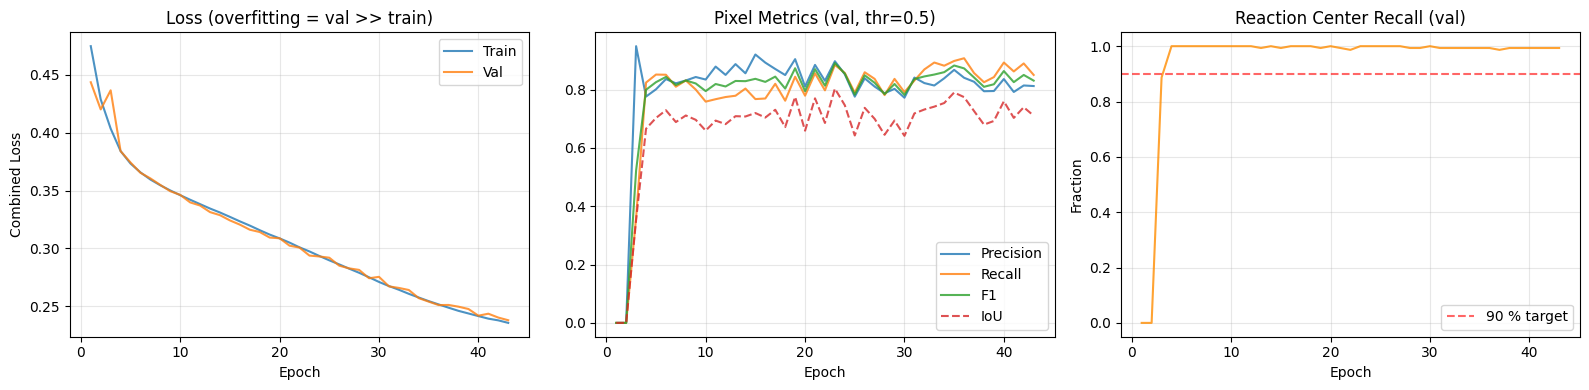

Saved: results/figures/exp_B_training.png


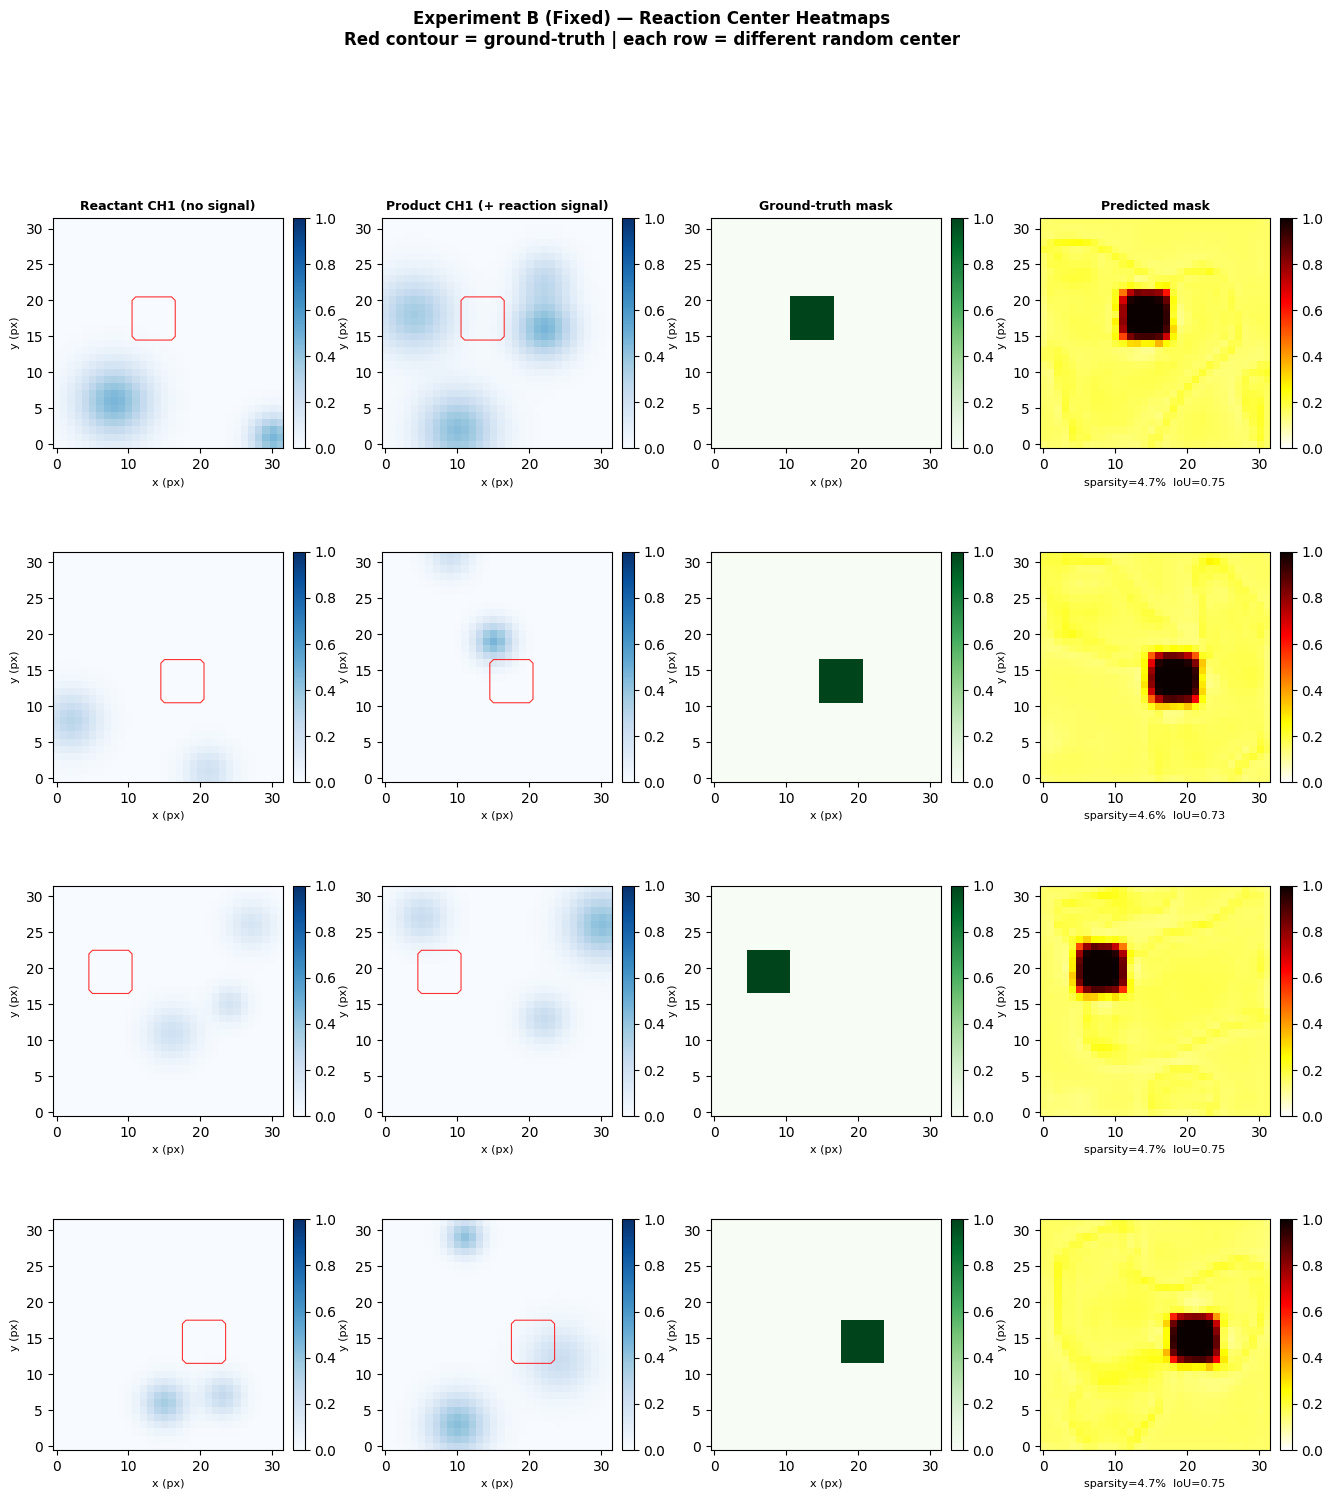

Saved: results/figures/exp_B_heatmaps.png

Experiment B (Fixed) — Final Evaluation
Optimal threshold:       0.85
Pixel Precision:         0.897
Pixel Recall:            0.885
Pixel F1:                0.891
Pixel IoU:               0.803
Reaction Center Recall:  1.000


In [ ]:
# ================================================================
#  CELL 8 — Main Execution
# ================================================================
if __name__ == '__main__':

    # ----------------------------------------------------------
    # 1. Build datasets
    #    FIX #3: 500/150 samples (not 10/10)
    #    FIX #3: different seeds for train vs val — no data leakage
    #    FIX #5: augment=True for train only
    # ----------------------------------------------------------
    print('Building datasets...')
    train_set = SyntheticReactionDataset(
        N_TRAIN, grid_size=GRID, seed=0,    augment=True)
    val_set   = SyntheticReactionDataset(
        N_VAL,   grid_size=GRID, seed=9999, augment=False)

    print(f'  Train : {len(train_set)} samples  (augmented=True)')
    print(f'  Val   : {len(val_set)} samples   (augmented=False)')

    loader_train = DataLoader(train_set, batch_size=BATCH_SIZE,
                              shuffle=True,  num_workers=0)
    loader_val   = DataLoader(val_set,   batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0)

    # ----------------------------------------------------------
    # 2. Build model
    # ----------------------------------------------------------
    model = ReactionMaskNet(in_ch=14, dropout=DROPOUT).to(DEVICE)
    params = sum(p.numel() for p in model.parameters())
    print(f'\nReactionMaskNet — {params:,} parameters')

    # ----------------------------------------------------------
    # 3. Train
    # ----------------------------------------------------------
    print(f'\nTraining for up to {EPOCHS} epochs '
          f'(early stopping patience={ES_PATIENCE})...\n')
    history = train(model, loader_train, loader_val)

    torch.save(model.state_dict(), 'results/reaction_mask_net_fixed.pt')
    print('\nSaved: results/reaction_mask_net_fixed.pt')

    # ----------------------------------------------------------
    # 4. Plots
    # ----------------------------------------------------------
    plot_training_history(history)
    visualise_predictions(model, val_set, n=4)

    # ----------------------------------------------------------
    # 5. Final evaluation
    # ----------------------------------------------------------
    final_evaluation(model, loader_val)